# Ejercicio 10
## 1. Calidad de los datos
Se eliminan duplicados exactos y filas incompletas para comparar las mismas lecturas en todas las variables. No se imputan medidas; esto puede introducir sesgo si las ausencias no son aleatorias.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from preparacion_ia_maquinas import cargar_datos, resumen, seleccionar
original = pd.read_csv('lecturas_maquinas.csv')
print('Filas originales:', len(original))
print('Duplicados:', original.duplicated().sum())
print(original.isna().sum())
datos = cargar_datos('lecturas_maquinas.csv')
print('Filas utilizables:', len(datos))
print('Identificadores repetidos:', datos.registro.duplicated().sum())

Filas originales: 122
Duplicados: 2
registro                   0
maquina                    0
turno                      0
franja                     0
carga_pct                  0
temperatura_c              2
vibracion_mm_s             1
consumo_kwh                0
presion_bar                1
incidencia_proxima_hora    0
dtype: int64
Filas utilizables: 116
Identificadores repetidos: 0


## 2. Comparación de incidencias por periodo

Histórico: 86 Evaluación: 30


,count,sum,mean
maquina,,,
M01,29,6,0.206897
M02,29,9,0.310345
M03,28,5,0.178571


,count,sum,mean
maquina,,,
M01,10,2,0.2
M02,10,6,0.6
M03,10,1,0.1


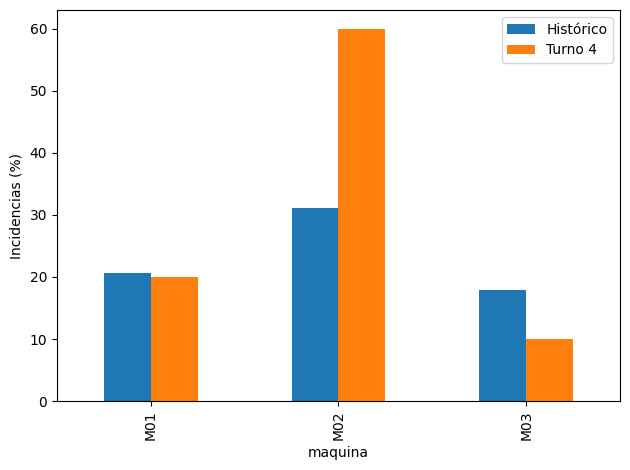

In [2]:
from preparacion_ia_maquinas import dividir
historico, evaluacion = dividir(datos)
print('Histórico:',len(historico),'Evaluación:',len(evaluacion))
display(resumen(historico,'maquina')); display(resumen(evaluacion,'maquina'))
tabla = pd.DataFrame({'Histórico':resumen(historico,'maquina')['mean']*100,'Turno 4':resumen(evaluacion,'maquina')['mean']*100})
tabla.plot.bar(ylabel='Incidencias (%)'); plt.tight_layout(); plt.savefig('periodos.jpg'); plt.show()

M02 aumenta de 9/29 a 6/10 incidencias; M01 pasa de 6/29 a 2/10 y M03 de 5/28 a 1/10. El cambio de M02 puede afectar a la representatividad del histórico; las muestras son pequeñas.
## 3. Cambios de mediciones

,vibracion_mm_s,presion_bar,temperatura_c
maquina,,,
M01,3.710690,7.449655,70.837931
M02,4.737241,7.275172,78.141379
M03,3.678214,7.300714,69.617857


,vibracion_mm_s,presion_bar,temperatura_c
maquina,,,
M01,4.211,7.288,74.67
M02,5.988,6.801,84.83
M03,3.108,7.488,66.99


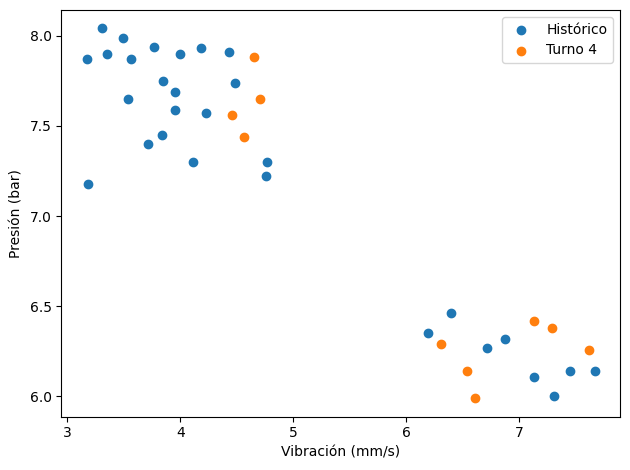

In [3]:
variables = ['vibracion_mm_s','presion_bar','temperatura_c']
display(historico.groupby('maquina')[variables].mean()); display(evaluacion.groupby('maquina')[variables].mean())
for nombre, grupo in [('Histórico',historico),('Turno 4',evaluacion)]:
    m = grupo[grupo.maquina=='M02']
    plt.scatter(m.vibracion_mm_s,m.presion_bar,label=nombre)
plt.xlabel('Vibración (mm/s)'); plt.ylabel('Presión (bar)'); plt.legend(); plt.tight_layout(); plt.savefig('cambio_m02.jpg'); plt.show()

M02 presenta mayor vibración y temperatura y menor presión en el turno 4 respecto al histórico.
## 4. Auditoría
Se seleccionan lecturas que se alejan más de dos desviaciones típicas de la media histórica de su propia máquina en alguna de las tres variables. Es un criterio exploratorio, sin etiqueta ni referencias del turno 4.

In [4]:
avisos = seleccionar(historico,evaluacion)
display(avisos)
print('Lecturas marcadas:',len(avisos))

,registro,maquina,turno,franja,carga_pct,temperatura_c,vibracion_mm_s,consumo_kwh,presion_bar,incidencia_proxima_hora,motivo
31,M01-04-01,M01,4,1,95,91.8,6.56,10.96,6.17,1,vibracion_mm_s; temperatura_c; presion_bar;
39,M01-04-09,M01,4,9,71,84.9,6.35,9.19,6.02,1,vibracion_mm_s; temperatura_c; presion_bar;
74,M02-04-04,M02,4,4,95,96.7,7.62,10.71,6.26,1,temperatura_c;


Lecturas marcadas: 3


## 5. Comprobación y exportación

In [5]:
print('Con incidencia:',avisos.incidencia_proxima_hora.sum())
print('Sin incidencia:',len(avisos)-avisos.incidencia_proxima_hora.sum())
historico.to_csv('historico_ia.csv',index=False)
evaluacion.to_csv('evaluacion_ia.csv',index=False)
avisos.to_json('lecturas_auditoria.json',orient='records',indent=2)

Con incidencia: 3
Sin incidencia: 0


## Conclusión
No se ha entrenado ningún modelo. La etiqueta debe separarse de las variables predictoras y el turno 4 reservarse para evaluación. Pedir más turnos, fechas, tipos de avería, mantenimiento, calibración y condiciones de producción. La selección no garantiza predicción y el histórico es reducido.